# So sánh ảnh gốc, color balance, CLAHE và kết hợp trên 10 ảnh validation

Mỗi hàng hiển thị cùng một ảnh theo bốn cách: **ảnh gốc**, **color balance (`simplest_cb`)**, **CLAHE** và **color balance → CLAHE**. Cột kết hợp áp dụng cân bằng màu trước, sau đó CLAHE trên kết quả đã cân bằng màu. Mọi bước xử lý đều thực hiện trước khi resize về 256 × 256.

Color balance giữ đúng thuật toán `simplest_cb` trong `baseline_unet34.ipynb`; mức cắt được đặt bằng `COLOR_BALANCE_PERCENT` (baseline dùng 1%). CLAHE chỉ xử lý kênh **L** (độ sáng) trong không gian **LAB**, với các tham số `CLAHE_CLIP_LIMIT` và `CLAHE_TILE_GRID_SIZE` ở cell cấu hình. Cột CLAHE riêng và cột kết hợp dùng cùng tham số CLAHE. Có thể chỉnh các tham số ở cell cấu hình để so sánh.

Chạy **Run All**, chỉ cần CPU và các thư viện `numpy`, `opencv-python`, `matplotlib`. Notebook chỉ đọc ảnh và hiển thị, không cần model, checkpoint hay mask.

Tự tìm thư mục official validation như baseline trong `/kaggle/input`, hoặc `val/images` trong `data/` ở máy local. Tập local `val/images` là tập đã chia sẵn; không mặc định coi đó là official validation 100 ảnh. Có thể chỉ định `VAL_IMAGE_DIR` nếu dữ liệu nằm ở vị trí khác.

Để `SEED = None` để chọn ngẫu nhiên mỗi lần chạy; đặt `SEED = 42` nếu muốn tái lập cùng 10 ảnh. Cả bốn cột được resize giống nhau và hiển thị trực tiếp ở dạng RGB `uint8` để so sánh màu.

In [19]:
import math
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

VAL_IMAGE_DIR = None  # Ví dụ: Path('/kaggle/input/.../ISIC2018_Task1-2_Validation_Input')
DATA_ROOT = None      # None: tự tìm trong /kaggle/input và data/ của dự án
N_IMAGES = 10
SEED = None          # None: ngẫu nhiên mỗi lần; 42: tái lập kết quả
COLOR_BALANCE_PERCENT = 1.0
CLAHE_CLIP_LIMIT = 1.0
CLAHE_TILE_GRID_SIZE = (8, 8)
DISPLAY_SIZE = 256   # Resize sau tiền xử lý, giống mức cuối của baseline
IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png'}
OFFICIAL_VAL_DIR_NAME = 'ISIC2018_Task1-2_Validation_Input'


In [20]:
def list_images(directory):
    return sorted(
        path for path in directory.iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES
        and not path.stem.lower().endswith('_segmentation')
    )


def find_val_image_dir():
    if VAL_IMAGE_DIR is not None:
        directory = Path(VAL_IMAGE_DIR).expanduser()
        if not directory.is_dir():
            raise FileNotFoundError(f'VAL_IMAGE_DIR không tồn tại: {directory}')
        return directory.resolve(), 'validation do người dùng chỉ định'

    roots = ([Path(DATA_ROOT).expanduser()] if DATA_ROOT is not None else [
        Path('/kaggle/input'),
        Path.cwd() / 'data',
        Path.cwd().parent / 'data',
    ])
    for root in roots:
        if not root.is_dir():
            continue
        official_dirs = ([root] if root.name == OFFICIAL_VAL_DIR_NAME else [])
        official_dirs.extend(sorted(root.rglob(OFFICIAL_VAL_DIR_NAME)))
        for outer in official_dirs:
            for directory in (outer / OFFICIAL_VAL_DIR_NAME, outer):
                if directory.is_dir() and list_images(directory):
                    return directory.resolve(), 'official validation (như baseline)'

        for relative in ('isic2018/isic2018/val/images',
                         'isic2018/val/images', 'val/images'):
            directory = root / relative
            if directory.is_dir() and list_images(directory):
                return directory.resolve(), 'local val/images (tập đã chia sẵn)'

    raise FileNotFoundError(
        'Không tìm thấy ảnh validation. Attach dataset như baseline trên Kaggle '
        'hoặc đặt VAL_IMAGE_DIR trỏ tới thư mục chứa ảnh val.'
    )


val_image_dir, split_source = find_val_image_dir()
val_image_paths = list_images(val_image_dir)
if len(val_image_paths) < N_IMAGES:
    raise ValueError(f'Cần ít nhất {N_IMAGES} ảnh val, chỉ thấy {len(val_image_paths)}.')
if len({path.stem for path in val_image_paths}) != len(val_image_paths):
    raise ValueError('Thư mục val có image ID trùng nhau.')
print(f'Nguồn: {split_source}')
print(f'Thư mục: {val_image_dir}')
print(f'Số ảnh validation: {len(val_image_paths)}')


Nguồn: local val/images (tập đã chia sẵn)
Thư mục: D:\Thị giác\data\isic2018\isic2018\val\images
Số ảnh validation: 808


In [21]:
# Giữ nguyên ba hàm color balance từ baseline_unet34.ipynb.
def apply_mask(matrix, mask, fill_value):
    masked = np.ma.array(matrix, mask=mask, fill_value=fill_value)
    return masked.filled()


def apply_threshold(matrix, low_value, high_value):
    low_mask = matrix < low_value
    matrix = apply_mask(matrix, low_mask, low_value)

    high_mask = matrix > high_value
    matrix = apply_mask(matrix, high_mask, high_value)

    return matrix


def simplest_cb(img, percent):
    """Thuật toán từ fredguth/skin-cancer/color_balance.py."""
    assert img.shape[2] == 3
    assert percent > 0 and percent < 100

    half_percent = percent / 200.0
    channels = cv2.split(img)

    out_channels = []
    for channel in channels:
        assert len(channel.shape) == 2

        height, width = channel.shape
        vec_size = width * height
        flat = channel.reshape(vec_size)

        assert len(flat.shape) == 1

        flat = np.sort(flat)
        n_cols = flat.shape[0]

        low_val = flat[math.floor(n_cols * half_percent)]
        high_val = flat[math.ceil(n_cols * (1.0 - half_percent))]

        # Bản gốc print low/high ở đây để debug; bỏ print không đổi kết quả.
        thresholded = apply_threshold(channel, low_val, high_val)
        normalized = cv2.normalize(
            thresholded, thresholded.copy(), 0, 255, cv2.NORM_MINMAX
        )
        out_channels.append(normalized)

    return cv2.merge(out_channels)


In [22]:
def apply_clahe_bgr(image_bgr, clip_limit=CLAHE_CLIP_LIMIT,
                    tile_grid_size=CLAHE_TILE_GRID_SIZE):
    """Áp dụng CLAHE riêng lên kênh L của ảnh LAB, trả về ảnh BGR uint8."""
    lab = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2LAB)
    lightness, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    enhanced_l = clahe.apply(lightness)
    enhanced_lab = cv2.merge((enhanced_l, a, b))
    return cv2.cvtColor(enhanced_lab, cv2.COLOR_LAB2BGR)


In [23]:
# Chạy lại cell này và cell hiển thị để lấy 10 ảnh khác khi SEED = None.
rng = [162, 681, 286, 236, 53, 496, 77, 311, 517, 282]
selected_indices = [162, 681, 286, 236, 53, 496, 77, 311, 517, 282]
selected_paths = [val_image_paths[int(index)] for index in selected_indices]
print('10 ảnh được chọn: ' + ', '.join(path.stem for path in selected_paths))


10 ảnh được chọn: 244, 711, 356, 310, 146, 545, 168, 379, 564, 352


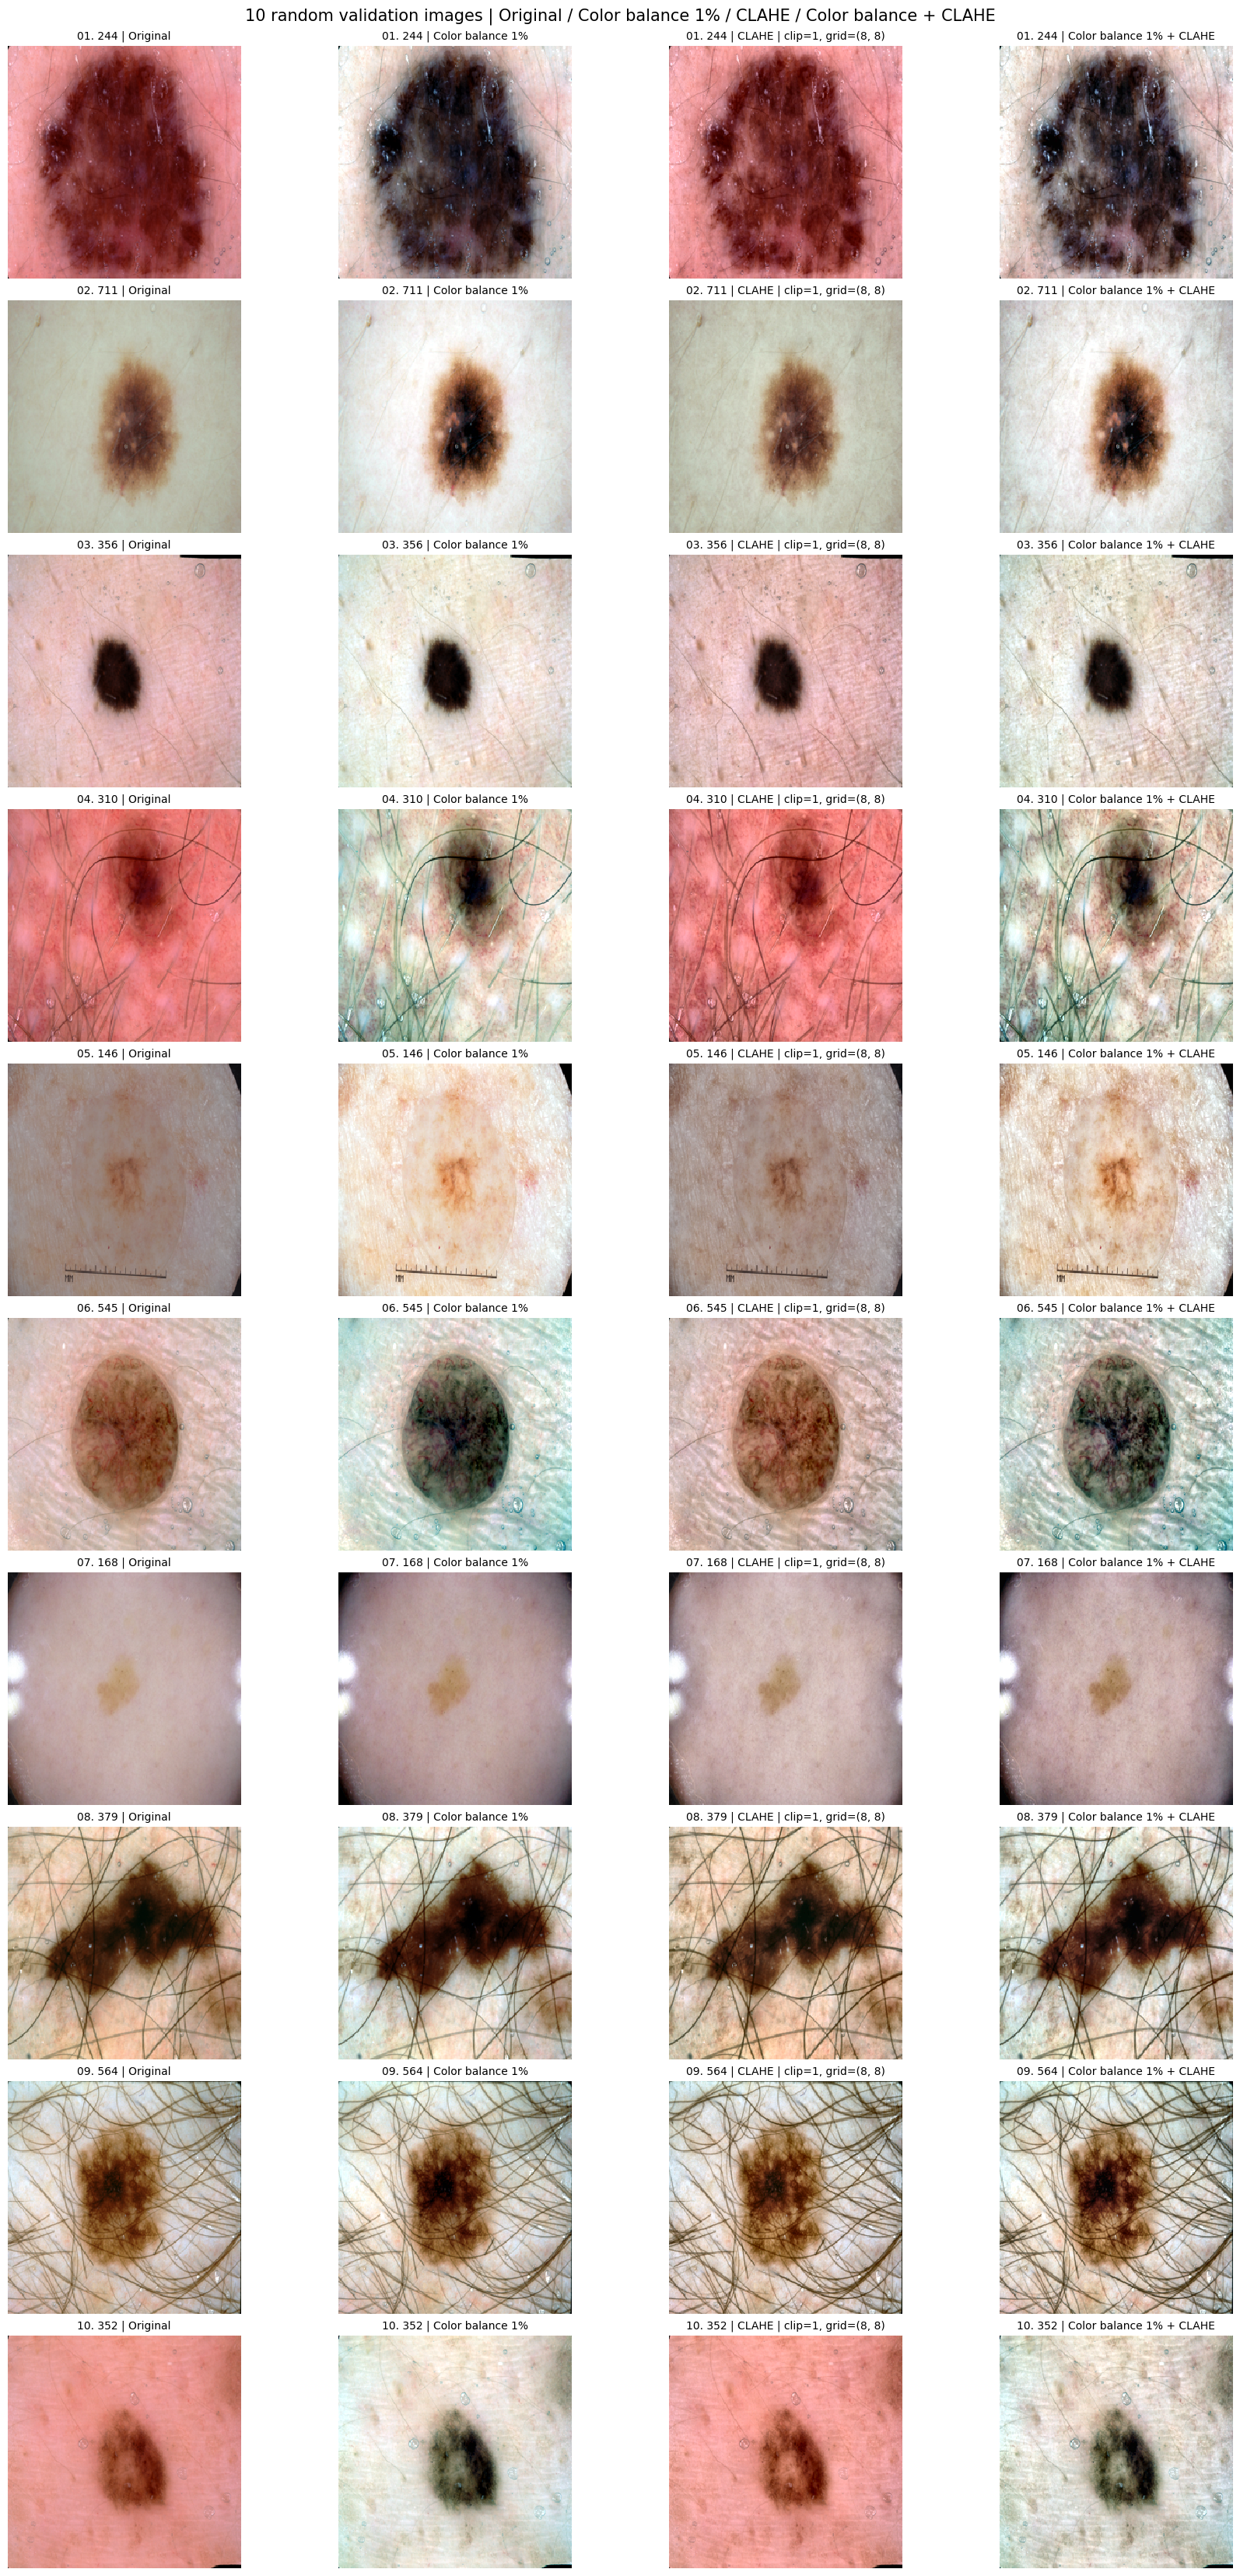

In [24]:
fig, axes = plt.subplots(
    N_IMAGES, 4, figsize=(17, N_IMAGES * 3.3), squeeze=False, layout='constrained'
)
fig.suptitle(
    f'{N_IMAGES} random validation images | '
    f'Original / Color balance {COLOR_BALANCE_PERCENT:g}% / CLAHE / Color balance + CLAHE',
    fontsize=15,
)

try:
    for row, image_path in enumerate(selected_paths):
        # np.fromfile + imdecode đọc được cả đường dẫn có dấu trên Windows.
        # IMREAD_COLOR giữ cách giải mã BGR giống cv2.imread trong baseline.
        encoded = np.fromfile(image_path, dtype=np.uint8)
        original_bgr = cv2.imdecode(encoded, cv2.IMREAD_COLOR)
        if original_bgr is None:
            raise ValueError(f'Không đọc được ảnh: {image_path}')

        # Cột riêng xử lý ảnh gốc; cột kết hợp thực hiện color balance rồi CLAHE.
        # Chỉ resize sau khi đã hoàn tất các bước tiền xử lý.
        balanced_bgr = simplest_cb(original_bgr, COLOR_BALANCE_PERCENT)
        clahe_bgr = apply_clahe_bgr(original_bgr)
        combined_bgr = apply_clahe_bgr(balanced_bgr)
        variants = (original_bgr, balanced_bgr, clahe_bgr, combined_bgr)
        titles = (
            'Original',
            f'Color balance {COLOR_BALANCE_PERCENT:g}%',
            f'CLAHE | clip={CLAHE_CLIP_LIMIT:g}, grid={CLAHE_TILE_GRID_SIZE}',
            f'Color balance {COLOR_BALANCE_PERCENT:g}% + CLAHE',
        )
        for column, (image_bgr, title) in enumerate(zip(variants, titles)):
            image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
            image_rgb = cv2.resize(
                image_rgb, (DISPLAY_SIZE, DISPLAY_SIZE), interpolation=cv2.INTER_LINEAR
            )
            axes[row, column].imshow(image_rgb, interpolation='nearest')
            axes[row, column].set_title(f'{row + 1:02d}. {image_path.stem} | {title}', fontsize=10)
            axes[row, column].axis('off')

    plt.show()
finally:
    plt.close(fig)
